# 58_catboost_sin_rescuerid

**Padre:** 22_word2vec_workers1 (repite el 56, que dio −0.037)

**Integrantes:** COMPLETAR

**CAMBIO 58 (= 56 sin RescuerID en CatBoost):** en cada fold, además de las 5 semillas de LightGBM, un `CatBoostRegressor` (RMSE, semilla 42, hasta 3000 árboles, learning_rate 0.05, parada temprana a los 100 sin mejora con el valid del fold, igual que hace el LightGBM). Las categóricas se le pasan como `cat_features`. Predicción = 0.5 · LightGBM + 0.5 · CatBoost, antes de los cortes. Mismas features y mismos folds que el 22.

Diferencia con el 56: CatBoost **no recibe RescuerID** (en validación todos los rescatistas son nuevos, así que lo que
aprende de cada rescatista en train no sirve). LightGBM sigue igual que en el 22.

Celdas tocadas: la de entrenamiento (líneas `# CAMBIO 56` y `# CAMBIO 58`). Todo lo demás igual que el 22.

**VALIDACIÓN:** folds `StratifiedGroupKFold` por `RescuerID`, semilla 42 (líneas `# CAMBIO VALIDACIÓN`).

# Este es el notebook final que genera la entrega, pueden hacer un fork de este notebook o iniciar uno propio; pero respetando los siguientes requisitos:

1. Generar una archivo de entrega válido, tal y como lo hace este. Para aprobar, el resultado debe ser superior a 0.3 (lo que da este)
2. Consignar los integrantes del grupo 
2. Puede tomar datos preprocesados en los mismos notebooks que este, en una modificación o en algo totalmente distinto
3. Es lícito tomar inspiración de los notebooks trabajados en clase y de los demás incluídos en mi perfil

### Si quieren consultar el resultado que van teniendo pueden hacerlo desde la pantalla de revisión del notebook, en la pestaña `DATA`, haciendo click en `submit` 

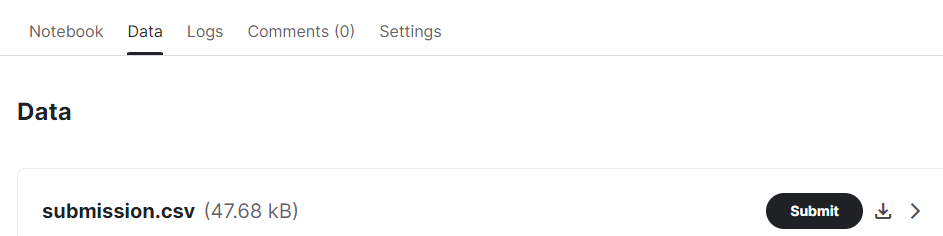

In [1]:
# Importación de Librerías
import pandas as pd 

from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedGroupKFold   # CAMBIO VALIDACIÓN: folds por rescatista
from sklearn.metrics import cohen_kappa_score
from lightgbm import LGBMClassifier, early_stopping

def metric(y_true, y_pred):
    res = cohen_kappa_score(y_true, y_pred.reshape((y_true.shape[0], 5), order="F").argmax(axis=1), weights= 'quadratic')
    return "kappa", res, True

In [2]:
# CAMBIO 01: librerías para regresión y para optimizar los umbrales
import numpy as np
from lightgbm import LGBMRegressor
from scipy.optimize import minimize

In [3]:
train = pd.read_csv('../input/petfinder-adoption-prediction/train/train.csv').set_index("PetID")
test = pd.read_csv('../input/petfinder-adoption-prediction/test/test.csv').set_index("PetID")
# CAMBIO VALIDACIÓN: folds agrupados por rescatista (el mismo RescuerID nunca está en train y valid)
# y estratificados por AdoptionSpeed, semilla 42. Es la regla de validación del proyecto (Claude.md).
folds = [train.index[test_idx] for train_idx, test_idx in
         StratifiedGroupKFold(5, shuffle=True, random_state=42).split(train, train["AdoptionSpeed"], groups=train["RescuerID"])]
# folds = [train.index[test_idx] for train_idx, test_idx in KFold(5).split(train)]   # original

# CAMBIO VALIDACIÓN: si existe la copia local data/folds.csv, verificar que los folds son exactamente esos
import os
if os.path.exists("../data/folds.csv"):
    guardado = pd.read_csv("../data/folds.csv", index_col="PetID")["fold"]
    assert all((guardado.loc[f] == k).all() for k, f in enumerate(folds)), "Los folds no coinciden con data/folds.csv"
    print("Folds verificados contra data/folds.csv")

Folds verificados contra data/folds.csv


In [4]:
for c in ['Type', 'Breed1', 'Breed2', 'Gender', 'Color1', 'Color2',
       'Color3', 'FurLength', 'MaturitySize', 'Vaccinated', 'Dewormed',
       'Sterilized', 'Health', 'State', 'RescuerID']:
    train[c] = train[c].astype("category")    
    test[c] = test[c].astype("category")

In [5]:
# CAMBIO 02: cantidad de mascotas publicadas por cada rescatista.
# Cada conjunto se cuenta por separado: train con train, test con test (test solo se usa para la entrega).
# Ningún rescatista está en los dos conjuntos, así que es la cantidad total de publicaciones de ese rescatista.
train["RescuerID_count"] = train.groupby("RescuerID", observed=True)["RescuerID"].transform("size")
test["RescuerID_count"] = test.groupby("RescuerID", observed=True)["RescuerID"].transform("size")
print("Rescatistas en train y test a la vez:", len(set(train["RescuerID"]) & set(test["RescuerID"])))
train["RescuerID_count"].describe()

Rescatistas en train y test a la vez: 0


count    14993.000000
mean        42.917295
std         96.482112
min          1.000000
25%          1.000000
50%          5.000000
75%         28.000000
max        459.000000
Name: RescuerID_count, dtype: float64

In [6]:
# CAMBIO 04: puntaje medio de las etiquetas de Google Vision en la PRIMERA foto (una sola variable)
import glob, json, os

def score_primera_foto(carpeta):
    valores = {}
    for ruta in glob.glob(os.path.join(carpeta, "*-1.json")):      # solo "<PetID>-1.json"
        pet_id = os.path.basename(ruta)[:-len("-1.json")]
        with open(ruta, encoding="utf-8") as f:
            etiquetas = [e.get("score", 0) for e in json.load(f).get("labelAnnotations", [])]
        valores[pet_id] = np.mean(etiquetas) if etiquetas else np.nan
    return pd.Series(valores, name="meta1_label_score_mean")

train = train.join(score_primera_foto("../input/petfinder-adoption-prediction/train_metadata"))
test = test.join(score_primera_foto("../input/petfinder-adoption-prediction/test_metadata"))
print("Con valor: train", train["meta1_label_score_mean"].notna().mean().round(3),
      "| test", test["meta1_label_score_mean"].notna().mean().round(3))
train["meta1_label_score_mean"].describe()

Con valor: train 0.977 | test 0.971


count    14650.000000
mean         0.783802
std          0.045051
min          0.517198
25%          0.754000
50%          0.781212
75%          0.812278
max          0.953746
Name: meta1_label_score_mean, dtype: float64

In [7]:
# CAMBIO 13 (bloque del 09): brillo, nitidez, aspecto y saturación de las fotos (OpenCV; ver prep_imagenes_opencv.ipynb)
train = train.join(pd.read_parquet("../input/lab2-prep-imagenes-opencv/train.parquet"))
test = test.join(pd.read_parquet("../input/lab2-prep-imagenes-opencv/test.parquet"))
print("Con fotos: train", train["img_cv_mean_brillo"].notna().mean().round(3),
      "| test", test["img_cv_mean_brillo"].notna().mean().round(3))
train.filter(like="img_cv_").describe().T.round(2)

Con fotos: train 0.977 | test 0.971


,count,mean,std,min,25%,50%,75%,max
img_cv_mean_brillo,14652.0,119.83,23.15,27.90,105.93,119.89,133.69,229.23
img_cv_mean_nitidez,14652.0,1101.00,1358.67,8.05,326.14,656.66,1326.06,27061.40
img_cv_mean_aspecto,14652.0,1.05,0.31,0.43,0.75,1.04,1.33,4.40
img_cv_mean_saturacion,14652.0,63.79,27.01,0.00,45.13,59.91,77.78,215.85
img_cv_max_brillo,14652.0,134.61,26.81,29.42,118.05,134.59,151.20,252.76
img_cv_max_nitidez,14652.0,1748.35,2118.55,8.05,472.40,1018.43,2150.60,27061.40
img_cv_max_aspecto,14652.0,1.21,0.38,0.43,0.75,1.33,1.34,4.94
img_cv_max_saturacion,14652.0,80.09,35.52,0.00,54.47,74.79,100.01,243.20
img_cv_first_brillo,14652.0,120.07,27.70,18.76,102.83,120.30,137.08,249.54
img_cv_first_nitidez,14652.0,1100.35,1560.55,5.60,257.80,565.76,1266.59,27061.40


In [8]:
# CAMBIO 14 (bloque del 11): agregados por mascota de Google Vision (dominantColors, labelAnnotations, cropHints)
import glob, json, os
from joblib import Parallel, delayed

def valores_foto(ruta):
    # Devuelve listas de valores de UNA foto. Google omite los campos que valen 0, por eso el valor por defecto es 0.
    pet_id = os.path.basename(ruta)[:-len(".json")].rsplit("-", 1)[0]
    with open(ruta, encoding="utf-8") as f:
        m = json.load(f)
    colores = m.get("imagePropertiesAnnotation", {}).get("dominantColors", {}).get("colors", [])
    recortes = m.get("cropHintsAnnotation", {}).get("cropHints", [])
    return (pet_id,
            [c.get("score", 0) for c in colores],
            [c.get("pixelFraction", 0) for c in colores],
            [e.get("score", 0) for e in m.get("labelAnnotations", [])],
            [r.get("confidence", 0) for r in recortes],
            [r.get("importanceFraction", 0) for r in recortes])

def vision_por_mascota(carpeta):
    fotos = Parallel(n_jobs=-1, batch_size=512)(delayed(valores_foto)(r) for r in glob.glob(os.path.join(carpeta, "*.json")))
    nombres = ["dom_score", "dom_pixfrac", "label_score", "crop_conf", "crop_importance"]
    filas = []
    for pet_id, *listas in fotos:                     # una fila por valor individual
        for nombre, lista in zip(nombres, listas):
            filas += [(pet_id, nombre, v) for v in lista]
    largo = pd.DataFrame(filas, columns=["PetID", "variable", "valor"])
    agg = largo.groupby(["PetID", "variable"])["valor"].agg(["mean", "max"]).unstack("variable")
    agg.columns = [f"vis_{var}_{estad}" for estad, var in agg.columns]
    pedidas = ["vis_dom_score_mean", "vis_dom_score_max", "vis_dom_pixfrac_mean", "vis_dom_pixfrac_max",
               "vis_label_score_max",
               "vis_crop_conf_mean", "vis_crop_conf_max", "vis_crop_importance_mean", "vis_crop_importance_max"]
    return agg[pedidas]

train = train.join(vision_por_mascota("../input/petfinder-adoption-prediction/train_metadata"))
test = test.join(vision_por_mascota("../input/petfinder-adoption-prediction/test_metadata"))
print("Con metadata: train", train["vis_label_score_max"].notna().mean().round(3),
      "| test", test["vis_label_score_max"].notna().mean().round(3))
train.filter(like="vis_").describe().T.round(3)

Con metadata: train 0.977 | test 0.971


,count,mean,std,min,25%,50%,75%,max
vis_dom_score_mean,14652.0,0.086,0.011,0.025,0.080,0.088,0.093,0.176
vis_dom_score_max,14652.0,0.374,0.158,0.062,0.257,0.350,0.466,1.000
vis_dom_pixfrac_mean,14652.0,0.067,0.018,0.009,0.055,0.067,0.079,0.176
vis_dom_pixfrac_max,14652.0,0.299,0.136,0.015,0.202,0.279,0.376,0.998
vis_label_score_max,14652.0,0.978,0.021,0.520,0.969,0.984,0.993,0.995
vis_crop_conf_mean,14652.0,0.802,0.022,0.300,0.800,0.800,0.800,1.000
vis_crop_conf_max,14652.0,0.809,0.044,0.300,0.800,0.800,0.800,1.000
vis_crop_importance_mean,14652.0,1.001,0.058,0.440,1.000,1.000,1.000,3.625
vis_crop_importance_max,14652.0,1.014,0.152,0.440,1.000,1.000,1.000,6.250


In [9]:
# CAMBIO 21: Word2Vec sobre Description, entrenado SOLO con el train de cada fold
# (en Kaggle gensim viene instalado; si no, hace falta internet para instalarlo)
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

# Tokens guardados aparte: más abajo select_dtypes saca la columna de texto de train/test
tokens_train = train["Description"].fillna("").astype(str).map(simple_preprocess)
tokens_test = test["Description"].fillna("").astype(str).map(simple_preprocess)
print("Descripciones sin ninguna palabra: train", (tokens_train.str.len() == 0).sum(), "| test", (tokens_test.str.len() == 0).sum())

W2V_DIM = 100

import zlib
def hash_fijo(texto):   # CAMBIO 22: el hash de Python cambia en cada proceso; crc32 no
    return zlib.crc32(texto.encode("utf-8"))
W2V_COLS = [f"w2v_{k}" for k in range(W2V_DIM)]

def vector_promedio(tokens, modelo):
    conocidas = [t for t in tokens if t in modelo.wv.key_to_index]
    return modelo.wv[conocidas].mean(axis=0) if conocidas else np.zeros(W2V_DIM)

def agregar_w2v(X_tr, X_va, X_te, tok_tr, tok_va, tok_te):
    # CAMBIO 22: workers=1 y hashfxn fijo -> mismo resultado en cada corrida
    modelo = Word2Vec(sentences=list(tok_tr), vector_size=W2V_DIM, window=5, min_count=2, workers=1, seed=42,
                      hashfxn=hash_fijo)
    # modelo = Word2Vec(sentences=list(tok_tr), vector_size=W2V_DIM, window=5, min_count=2, workers=4, seed=42)   # 21
    salida = []
    for X, tok in ((X_tr, tok_tr), (X_va, tok_va), (X_te, tok_te)):
        vectores = pd.DataFrame(np.vstack([vector_promedio(t, modelo) for t in tok]), index=X.index, columns=W2V_COLS)
        salida.append(pd.concat([X, vectores], axis=1))
    return salida, len(modelo.wv)

Descripciones sin ninguna palabra: train 29 | test 7


In [10]:
train = train\
    .join(pd.read_parquet("../input/examen-lab-ii-preprocesado-texto/train.parquet"))\
    .join(pd.read_parquet("../input/examen-lab-ii-preprocesado-img/train.parquet"))\
    .select_dtypes(exclude="O")
train

C:\Users\eoinb\AppData\Local\Temp\ipykernel_13056\2979734898.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are excluded by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `exclude` to remove them, or to `include` to keep them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  .select_dtypes(exclude="O")


,Type,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,FurLength,...,img_feat_1271,img_feat_1272,img_feat_1273,img_feat_1274,img_feat_1275,img_feat_1276,img_feat_1277,img_feat_1278,img_feat_1279,img_feat_1280
PetID,,,,,,,,,,,,,,,,,,,,,
86e1089a3,2,3,299,0,1,1,7,0,1,1,...,1.814045e+00,9.572341,9.491208,8.123631,4.076036,3.546145,2.706579,3.854367,9.053297,5.043255
6296e909a,2,1,265,0,1,1,2,0,2,2,...,3.486593e+00,0.929680,1.713759,2.235990,3.242576,2.425042,5.691403,2.404264,4.722382,1.906226
3422e4906,1,1,307,0,1,2,7,0,2,2,...,3.766809e+00,4.862676,4.244085,15.222205,4.156213,3.254798,14.388715,0.699135,0.782224,4.049839
5842f1ff5,1,4,307,0,2,1,2,0,2,1,...,1.831599e+00,0.958038,5.207643,11.266092,1.961520,4.753674,6.500397,4.734499,3.918758,0.395105
850a43f90,1,1,307,0,1,1,0,0,2,1,...,2.546072e+00,2.868015,13.776942,28.832863,10.899086,14.199981,12.431811,5.213608,3.194550,1.664633
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
dc0935a84,2,2,266,0,3,1,0,0,2,2,...,6.398231e+00,0.643272,11.085301,5.629824,4.583021,4.653736,4.132456,2.940807,3.144760,0.530870
a01ab5b30,2,60,265,264,3,1,4,7,2,2,...,5.386696e+00,4.122095,5.763404,6.450202,1.468004,4.429782,-0.000239,-0.000246,-0.005670,1.435030
d981b6395,2,2,265,266,3,5,6,7,3,2,...,-2.509267e-06,3.012903,1.799460,11.088702,1.245904,12.891251,8.990035,0.935677,2.613868,2.060115


In [11]:
test = test\
    .join(pd.read_parquet("../input/examen-lab-ii-preprocesado-texto/test.parquet"))\
    .join(pd.read_parquet("../input/examen-lab-ii-preprocesado-img/test.parquet"))\
    .select_dtypes(exclude="O")
test

C:\Users\eoinb\AppData\Local\Temp\ipykernel_13056\1470161921.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are excluded by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `exclude` to remove them, or to `include` to keep them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  .select_dtypes(exclude="O")


,Type,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,FurLength,...,img_feat_1271,img_feat_1272,img_feat_1273,img_feat_1274,img_feat_1275,img_feat_1276,img_feat_1277,img_feat_1278,img_feat_1279,img_feat_1280
PetID,,,,,,,,,,,,,,,,,,,,,
e2dfc2935,2,8,266,266,1,2,6,7,1,1,...,2.729791,-0.003599,8.041116,-9.546924e-14,0.729528,10.610721,-1.780669e-08,8.799240e+00,0.481364,3.577485
f153b465f,2,36,285,264,2,1,4,7,2,3,...,4.479016,1.071924,1.251326,5.186645e-01,0.603996,4.067527,-3.328842e-11,1.152236e+00,24.060162,2.237646
3c90f3f54,2,2,265,0,1,6,7,0,2,2,...,-0.000048,2.216768,5.988122,2.149537e-01,1.031739,6.802655,6.157441e-01,4.477241e+00,6.950058,2.005114
e02abc8a3,1,12,307,0,2,2,5,0,2,2,...,0.323606,-0.002139,4.463790,9.191290e+00,2.525810,2.546011,1.796585e+00,1.704561e+00,3.451149,3.497725
09f0df7d1,2,12,265,0,1,2,3,7,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ae57f8d52,1,5,307,307,1,1,2,0,2,1,...,4.612437,3.134105,10.989739,1.271390e+01,1.738591,6.463470,1.743176e+00,6.607119e+00,1.796038,3.711370
83432904d,1,30,307,307,1,1,2,7,2,1,...,6.417864,9.599735,3.615918,5.719872e+00,3.935784,3.671640,1.667190e+01,-1.430260e-09,2.138567,17.469568
399013029,2,5,300,0,3,1,2,4,2,2,...,3.276674,1.547841,6.382185,2.605666e+00,2.519441,6.962638,2.862875e+00,2.601821e+00,3.288656,2.948880


In [12]:
# CAMBIO 12: semillas a promediar en cada fold
SEMILLAS = [0, 1, 2, 3, 4]

fold_preds = []
test_preds = []
for i, fold in enumerate(folds):
    X_train = train.drop(fold).drop("AdoptionSpeed", axis=1).select_dtypes(exclude="O")
    y_train = train.drop(fold)["AdoptionSpeed"]

    X_valid = train.loc[fold].drop("AdoptionSpeed", axis=1).select_dtypes(exclude="O")
    y_valid = train.loc[fold, "AdoptionSpeed"]

    # CAMBIO 21: Word2Vec entrenado con las descripciones del train de este fold; vectores para train, valid y test
    (X_train, X_valid, X_test), vocabulario = agregar_w2v(
        X_train, X_valid, test[X_train.columns],
        tokens_train.loc[X_train.index], tokens_train.loc[X_valid.index], tokens_test.loc[test.index])
    print(f"fold {i}: vocabulario Word2Vec", vocabulario, "palabras")

    # CAMBIO 12: un modelo por semilla, con 80% de filas y columnas al azar; se promedian las predicciones
    pred_valid, pred_test, iteraciones = [], [], []
    for semilla in SEMILLAS:
        learner = LGBMRegressor(random_state=semilla, subsample=0.8, subsample_freq=1, colsample_bytree=0.8)
        # learner = LGBMRegressor()   # 04 (CAMBIO 01)
        # learner.fit(X_train, y_train, )   # CAMBIO 12: quitado; el fit siguiente lo reemplazaba (no cambia resultados)

        # CAMBIO 01: sin eval_metric=metric (esa función es para 5 probabilidades);
        # el early stopping usa el error cuadrático (l2) de la regresión
        learner.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_valid, y_valid)],
                    callbacks=[early_stopping(5, verbose=False)])
        iteraciones.append(learner.best_iteration_)   # CAMBIO 13: guardar la iteración de cada semilla
        pred_valid.append(learner.predict(X_valid))
        pred_test.append(learner.predict(X_test[X_train.columns]))   # CAMBIO 21: test con los vectores de este fold
        # pred_test.append(learner.predict(test[X_train.columns]))   # 14
    print(f"fold {i}: mejores iteraciones por semilla", iteraciones)   # CAMBIO 13: antes mostraba solo la última
    # CAMBIO 56: CatBoost con las mismas columnas; se promedia 50/50 con el promedio de LightGBM
    from catboost import CatBoostRegressor, Pool
    # CAMBIO 58: CatBoost sin RescuerID
    cats = [col for col in X_train.columns if str(X_train[col].dtype) == "category" and col != "RescuerID"]
    a_cb = lambda X: X.drop(columns=["RescuerID"], errors="ignore").assign(**{col: X[col].astype(str) for col in cats})
    cb = CatBoostRegressor(loss_function="RMSE", iterations=3000, learning_rate=0.05, random_seed=42,
                           od_type="Iter", od_wait=100, verbose=0, thread_count=-1)
    cb.fit(Pool(a_cb(X_train), y_train, cat_features=cats), eval_set=Pool(a_cb(X_valid), y_valid, cat_features=cats),
           use_best_model=True)
    p_cb_valid = cb.predict(a_cb(X_valid))
    p_cb_test = cb.predict(a_cb(X_test[X_train.columns]))
    p_lgb_valid = np.mean(pred_valid, axis=0)
    print(f"fold {i}: CatBoost {cb.get_best_iteration()} árboles | correlación con LightGBM {np.corrcoef(p_lgb_valid, p_cb_valid)[0, 1]:.3f}")
    fold_preds.append(pd.Series(0.5 * p_lgb_valid + 0.5 * p_cb_valid, index=fold, name="AdoptionSpeed"))
    test_preds.append(pd.Series(0.5 * np.mean(pred_test, axis=0) + 0.5 * p_cb_test, index=test.index))
    # fold_preds.append(pd.Series(np.mean(pred_valid, axis=0), index=fold, name="AdoptionSpeed"))   # 22
    # test_preds.append(pd.Series(np.mean(pred_test, axis=0), index=test.index))                   # 22
    # fold_preds.append(pd.Series(learner.predict(X_valid), index=fold, name="AdoptionSpeed"))   # 04
    # test_preds.append(pd.Series(learner.predict(test[X_train.columns]), index=test.index))     # 04

fold_preds = pd.concat(fold_preds)
# CAMBIO 01: promedio de los 5 modelos; los umbrales se aplican en la celda siguiente
test_preds = sum(test_preds) / len(test_preds)

fold 0: vocabulario Word2Vec 10498 palabras


C:\Users\eoinb\projects\labo2\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.101185 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 359940
[LightGBM] [Info] Number of data points in the train set: 11988, number of used features: 1430
[LightGBM] [Info] Start training from score 2.516600


C:\Users\eoinb\projects\labo2\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.


... (63 outputs left out)

C:\Users\eoinb\projects\labo2\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.110825 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 359943
[LightGBM] [Info] Number of data points in the train set: 11997, number of used features: 1430
[LightGBM] [Info] Start training from score 2.516629


fold 4: mejores iteraciones por semilla [40, 42, 49, 35, 48]


fold 4: CatBoost 316 árboles | correlación con LightGBM 0.941


In [13]:
# CAMBIO 01: umbrales optimizados para pasar del número continuo a la clase 0-4
def aplicar_cortes(pred, cortes):
    # 3 cortes ordenados -> clases 0..4 (debajo del 1er corte = 0, encima del 4to = 4)
    return np.digitize(pred, np.sort(cortes))

def optimizar_cortes(pred, y, inicio=(0.5, 1.5, 2.5, 3.5)):
    perdida = lambda c: -cohen_kappa_score(y, aplicar_cortes(pred, c), weights="quadratic")
    return np.sort(minimize(perdida, inicio, method="nelder-mead").x)

y_oof = train.loc[fold_preds.index, "AdoptionSpeed"]

# MEDICIÓN honesta: los cortes de cada fold se eligen con los OTROS 4 folds
# (si se eligen con todos, el kappa sale inflado porque los cortes 'vieron' las respuestas)
oof_clases = []
for fold in folds:
    resto = fold_preds.index.difference(fold)
    c = optimizar_cortes(fold_preds[resto], y_oof[resto])
    oof_clases.append(pd.Series(aplicar_cortes(fold_preds[fold], c), index=fold))
oof_clases = pd.concat(oof_clases)
kappa_oof = cohen_kappa_score(y_oof[oof_clases.index], oof_clases, weights="quadratic")

# Para la entrega: cortes elegidos con TODO el OOF
cortes = optimizar_cortes(fold_preds, y_oof)
kappa_optimista = cohen_kappa_score(y_oof, aplicar_cortes(fold_preds, cortes), weights="quadratic")
print("Cortes:", np.round(cortes, 3))
print(f"Kappa OOF (honesto, el que se compara): {kappa_oof:.4f}")
print(f"Kappa OOF (optimista, solo referencia):  {kappa_optimista:.4f}")

test_preds = pd.Series(aplicar_cortes(test_preds, cortes), index=test_preds.index, name="AdoptionSpeed")
test_preds.value_counts().sort_index()

Cortes: [0.37  2.148 2.558 2.844]
Kappa OOF (honesto, el que se compara): 0.4301
Kappa OOF (optimista, solo referencia):  0.4331


AdoptionSpeed
1     817
2    1230
3     773
4    1152
Name: count, dtype: int64

In [14]:
# MEDICIÓN (no cambia la entrega): kappa por fold, media ± desvío, y guardado para comparar
import json
pred_clase = oof_clases if "oof_clases" in globals() else fold_preds
kappas = [cohen_kappa_score(train.loc[f, "AdoptionSpeed"], pred_clase[f], weights="quadratic") for f in folds]
kappa_total = cohen_kappa_score(train.loc[pred_clase.index, "AdoptionSpeed"], pred_clase, weights="quadratic")
print("Kappa por fold:", [round(k, 4) for k in kappas])
print(f"Kappa media: {pd.Series(kappas).mean():.4f} ± {pd.Series(kappas).std():.4f}   |   Kappa OOF total: {kappa_total:.4f}")
json.dump({"notebook": "58_catboost_sin_rescuerid", "kappas_fold": kappas, "kappa_total": kappa_total},
          open("resultados_58_catboost_sin_rescuerid.json", "w"))

Kappa por fold: [0.4334, 0.4083, 0.4511, 0.4288, 0.4287]
Kappa media: 0.4301 ± 0.0153   |   Kappa OOF total: 0.4301


In [15]:
test_preds.to_csv("submission.csv")
!head submission.csv

'head' is not recognized as an internal or external command,
operable program or batch file.
